First load nececary modules:

In [1]:
import math
from operator import attrgetter

import cmocean

from matplotlib import pyplot as plt,animation,rc
import matplotlib.gridspec as gridspec
import numpy as np
import xarray as xr
from datetime import datetime,timedelta
from scipy import interpolate
from netCDF4 import Dataset
from IPython.display import HTML,Image
rc('animation',html = 'html5')
from cartopy import crs,feature
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
import pandas as pd
from copy import copy
#from matplotlib.animation import FuncAnimation

from parcels import (
    AdvectionRK4,
    AdvectionRK4_3D,
    FieldSet,
    Field,
    JITParticle,
    ParticleSet,
    GeographicPolar,
    Geographic,
    Variable
)

Advect particles with netcdf files of precomputed velocity fields from Copernicus Marine Data Store

In [2]:
example_dataset_folder = "/Users/jvalenti/Desktop/UBC/OP_California_Kate/"
uvdata = f"{example_dataset_folder}cmems_mod_glo_phy-cur_anfc_0.083deg_P1D-m_1722376382481.nc"
wdata = f"{example_dataset_folder}cmems_mod_glo_phy-wcur_anfc_0.083deg_P1D-m_1722376618489.nc"

def make_landmask(fielddata):
    """Returns landmask where land = 1 and ocean = 0
    fielddata is a netcdf file.
    """
    datafile = Dataset(fielddata)

    landmask = datafile.variables["uo"][0, 0]
    landmask = np.ma.masked_invalid(landmask)
    landmask = landmask.mask.astype("int")

    return landmask

model = xr.open_dataset(uvdata)

In [3]:
# define meshgrid coordinates to plot velocity field with matplotlib pcolormesh
latmin = 150
latmax = 200
lonmin = 60
lonmax = 100
# Velocity nodes
lon_vals, lat_vals = np.meshgrid(model["longitude"], model["latitude"])
lons_plot = lon_vals[latmin:latmax, lonmin:lonmax]
lats_plot = lat_vals[latmin:latmax, lonmin:lonmax]

dlon = 1 / 12
dlat = 1 / 12

# Centers of the gridcells formed by 4 nodes = velocity nodes + 0.5 dx
x = model["longitude"][:-1] + np.diff(model["longitude"]) / 2
y = model["latitude"][:-1] + np.diff(model["latitude"]) / 2
lon_centers, lat_centers = np.meshgrid(x, y)

color_land = copy(plt.get_cmap("Reds"))(0)
color_ocean = copy(plt.get_cmap("Reds"))(128)

In [4]:
landmask = make_landmask(uvdata)

In [5]:
# Interpolate the landmask to the cell centers
# only cells with 4 neighboring land points will be land
fl = interpolate.RectBivariateSpline(
    model["latitude"], model["longitude"], landmask, kx=1, ky=1
)

# Centers of the gridcells formed by 4 nodes = velocity nodes + 0.5 dx
x = model["longitude"][:-1] + np.diff(model["longitude"]) / 2
y = model["latitude"][:-1] + np.diff(model["latitude"]) / 2
lon_centers, lat_centers = np.meshgrid(x, y)

l_centers = fl(lat_centers[:, 0], lon_centers[0, :])

# land when interpolated value == 1
lmask = np.ma.masked_values(l_centers, 1)

In [6]:
def get_coastal_nodes(landmask):
    """Function that detects the coastal nodes, i.e. the ocean nodes directly
    next to land. Computes the Laplacian of landmask.

    - landmask: the land mask built using `make_landmask`, where land cell = 1
                and ocean cell = 0.

    Output: 2D array array containing the coastal nodes, the coastal nodes are
            equal to one, and the rest is zero.
    """
    mask_lap = np.roll(landmask, -1, axis=0) + np.roll(landmask, 1, axis=0)
    mask_lap += np.roll(landmask, -1, axis=1) + np.roll(landmask, 1, axis=1)
    mask_lap -= 4 * landmask
    coastal = np.ma.masked_array(landmask, mask_lap > 0)
    coastal = coastal.mask.astype("int")

    return coastal


def get_shore_nodes(landmask):
    """Function that detects the shore nodes, i.e. the land nodes directly
    next to the ocean. Computes the Laplacian of landmask.

    - landmask: the land mask built using `make_landmask`, where land cell = 1
                and ocean cell = 0.

    Output: 2D array array containing the shore nodes, the shore nodes are
            equal to one, and the rest is zero.
    """
    mask_lap = np.roll(landmask, -1, axis=0) + np.roll(landmask, 1, axis=0)
    mask_lap += np.roll(landmask, -1, axis=1) + np.roll(landmask, 1, axis=1)
    mask_lap -= 4 * landmask
    shore = np.ma.masked_array(landmask, mask_lap < 0)
    shore = shore.mask.astype("int")

    return shore

def get_coastal_nodes_diagonal(landmask):
    """Function that detects the coastal nodes, i.e. the ocean nodes where
    one of the 8 nearest nodes is land. Computes the Laplacian of landmask
    and the Laplacian of the 45 degree rotated landmask.

    - landmask: the land mask built using `make_landmask`, where land cell = 1
                and ocean cell = 0.

    Output: 2D array array containing the coastal nodes, the coastal nodes are
            equal to one, and the rest is zero.
    """
    mask_lap = np.roll(landmask, -1, axis=0) + np.roll(landmask, 1, axis=0)
    mask_lap += np.roll(landmask, -1, axis=1) + np.roll(landmask, 1, axis=1)
    mask_lap += np.roll(landmask, (-1, 1), axis=(0, 1)) + np.roll(
        landmask, (1, 1), axis=(0, 1)
    )
    mask_lap += np.roll(landmask, (-1, -1), axis=(0, 1)) + np.roll(
        landmask, (1, -1), axis=(0, 1)
    )
    mask_lap -= 8 * landmask
    coastal = np.ma.masked_array(landmask, mask_lap > 0)
    coastal = coastal.mask.astype("int")

    return coastal


def get_shore_nodes_diagonal(landmask):
    """Function that detects the shore nodes, i.e. the land nodes where
    one of the 8 nearest nodes is ocean. Computes the Laplacian of landmask
    and the Laplacian of the 45 degree rotated landmask.

    - landmask: the land mask built using `make_landmask`, where land cell = 1
                and ocean cell = 0.

    Output: 2D array array containing the shore nodes, the shore nodes are
            equal to one, and the rest is zero.
    """
    mask_lap = np.roll(landmask, -1, axis=0) + np.roll(landmask, 1, axis=0)
    mask_lap += np.roll(landmask, -1, axis=1) + np.roll(landmask, 1, axis=1)
    mask_lap += np.roll(landmask, (-1, 1), axis=(0, 1)) + np.roll(
        landmask, (1, 1), axis=(0, 1)
    )
    mask_lap += np.roll(landmask, (-1, -1), axis=(0, 1)) + np.roll(
        landmask, (1, -1), axis=(0, 1)
    )
    mask_lap -= 8 * landmask
    shore = np.ma.masked_array(landmask, mask_lap < 0)
    shore = shore.mask.astype("int")

    return shore

In [7]:
coastal = get_coastal_nodes_diagonal(landmask)
shore = get_shore_nodes_diagonal(landmask)

In [8]:
def create_displacement_field(landmask, double_cell=False):
    """Function that creates a displacement field 1 m/s away from the shore.

    - landmask: the land mask dUilt using `make_landmask`.
    - double_cell: Boolean for determining if you want a double cell.
      Default set to False.

    Output: two 2D arrays, one for each camponent of the velocity.
    """
    shore = get_shore_nodes(landmask)

    # nodes bordering ocean directly and diagonally
    shore_d = get_shore_nodes_diagonal(landmask)
    # corner nodes that only border ocean diagonally
    shore_c = shore_d - shore

    # Simple derivative
    Ly = np.roll(landmask, -1, axis=0) - np.roll(landmask, 1, axis=0)
    Lx = np.roll(landmask, -1, axis=1) - np.roll(landmask, 1, axis=1)

    Ly_c = np.roll(landmask, -1, axis=0) - np.roll(landmask, 1, axis=0)
    # Include y-component of diagonal neighbors
    Ly_c += np.roll(landmask, (-1, -1), axis=(0, 1)) + np.roll(
        landmask, (-1, 1), axis=(0, 1)
    )
    Ly_c += -np.roll(landmask, (1, -1), axis=(0, 1)) - np.roll(
        landmask, (1, 1), axis=(0, 1)
    )

    Lx_c = np.roll(landmask, -1, axis=1) - np.roll(landmask, 1, axis=1)
    # Include x-component of diagonal neighbors
    Lx_c += np.roll(landmask, (-1, -1), axis=(1, 0)) + np.roll(
        landmask, (-1, 1), axis=(1, 0)
    )
    Lx_c += -np.roll(landmask, (1, -1), axis=(1, 0)) - np.roll(
        landmask, (1, 1), axis=(1, 0)
    )

    v_x = -Lx * (shore)
    v_y = -Ly * (shore)

    v_x_c = -Lx_c * (shore_c)
    v_y_c = -Ly_c * (shore_c)

    v_x = v_x + v_x_c
    v_y = v_y + v_y_c

    magnitude = np.sqrt(v_y**2 + v_x**2)
    # the coastal nodes between land create a problem. Magnitude there is zero
    # I force it to be 1 to avoid problems when normalizing.
    ny, nx = np.where(magnitude == 0)
    magnitude[ny, nx] = 1

    v_x = v_x / magnitude
    v_y = v_y / magnitude

    return v_x, v_y

def distance_to_shore(landmask, dx=1):
    """Function that computes the distance to the shore. It is based in the
    the `get_coastal_nodes` algorithm.

    - landmask: the land mask dUilt using `make_landmask` function.
    - dx: the grid cell dimension. This is a crude approxsimation of the real
    distance (be careful).

    Output: 2D array containing the distances from shore.
    """
    ci = get_coastal_nodes(landmask)  # direct neighbors
    dist = ci * dx  # 1 dx away

    ci_d = get_coastal_nodes_diagonal(landmask)  # diagonal neighbors
    dist_d = (ci_d - ci) * np.sqrt(2 * dx**2)  # sqrt(2) dx away

    return dist + dist_d

In [9]:
v_x, v_y = create_displacement_field(landmask)
d_2_s = distance_to_shore(landmask,3)

In [10]:
filenames = {
    "U": uvdata,
    "V": uvdata,
    "W": wdata
}

dimensions = {'lon':'longitude','lat':'latitude','depth':'depth','time':'time'}
variables = {
    "U": "uo",
    "V": "vo",
    "W": "wo"
}

field_set = FieldSet.from_netcdf(filenames, variables, dimensions,
        interp_method={
            "U": "partialslip",
            "V": "partialslip",
            "W": "partialslip",
            }
    )

u_displacement = v_x
v_displacement = v_y
field_set.add_field(
    Field(
        "dispU",
        data=u_displacement,
        lon=field_set.U.grid.lon,
        lat=field_set.U.grid.lat,
        mesh="spherical",
    )
)
field_set.add_field(
    Field(
        "dispV",
        data=v_displacement,
        lon=field_set.U.grid.lon,
        lat=field_set.U.grid.lat,
        mesh="spherical",
    )
)
field_set.dispU.units = GeographicPolar()
field_set.dispV.units = Geographic()
field_set.add_field(
    Field(
        "landmask",
        landmask,
        lon=field_set.U.grid.lon,
        lat=field_set.U.grid.lat,
        mesh="spherical",
    )
)
field_set.add_field(
    Field(
        "distance2shore",
        d_2_s,
        lon=field_set.U.grid.lon,
        lat=field_set.U.grid.lat,
        mesh="spherical",
    )
)

In [11]:
from scipy.io import loadmat

mdict = loadmat("list_data.mat")
latlist = mdict['latlist']
lonlist = mdict['lonlist']

In [12]:
DisplacementParticle = JITParticle.add_variables(
    [
        Variable("dU"),
        Variable("dV"),
        Variable("dds", initial=1e3),
    ]
)


depthlist = np.tile(10,(len(latlist),1))
pset = ParticleSet.from_list(field_set,DisplacementParticle,lon = lonlist, lat = latlist,depth = depthlist, repeatdt=timedelta(hours=240))

In [13]:
def KeepInOcean(particle, fieldset, time):
    if particle.state == StatusCode.ErrorThroughSurface:
        particle.depth = 0.5
        particle.state = StatusCode.Success

# Kernel for treating particles on shore

def set_displacement(particle, fieldset, time):
    particle.dds = fieldset.distance2shore[
        time, particle.depth, particle.lat, particle.lon
    ]
    if particle.dds < 4:
        dispUab = fieldset.dispU[time, particle.depth, particle.lat, particle.lon]
        dispVab = fieldset.dispV[time, particle.depth, particle.lat, particle.lon]
        particle.dU = dispUab
        particle.dV = dispVab
    else:
        particle.dU = 0.0
        particle.dV = 0.0


def displace(particle, fieldset, time):
    if particle.dds < 4:
        particle_dlon -= 4*particle.dU * particle.dt
        particle_dlat -= 4*particle.dV * particle.dt



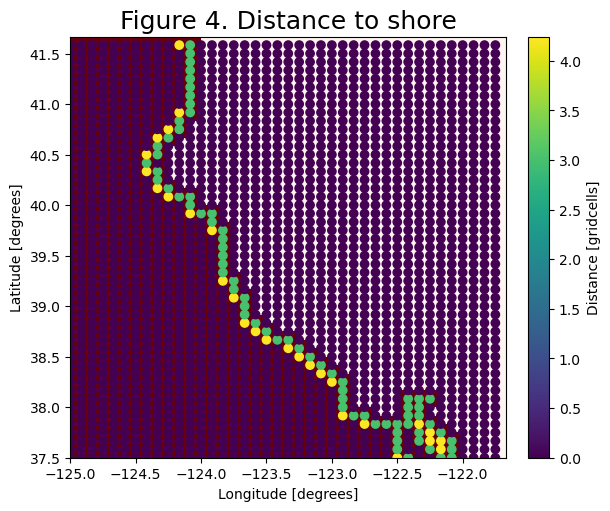

In [14]:
fig = plt.figure(figsize=(6, 5), constrained_layout=True)

ax0 = fig.add_subplot()
ax0.set_title("Figure 4. Distance to shore", fontsize=18)
ax0.set_ylabel("Latitude [degrees]")
ax0.set_xlabel("Longitude [degrees]")

land = ax0.pcolormesh(
    lon_vals[latmin : latmax + 1, lonmin : lonmax + 1],
    lat_vals[latmin : latmax + 1, lonmin : lonmax + 1],
    lmask.mask[latmin:latmax, lonmin:lonmax],
    cmap="Reds_r",
)
d2s = ax0.scatter(lons_plot, lats_plot, c=d_2_s[latmin:latmax, lonmin:lonmax])

plt.colorbar(d2s, ax=ax0, label="Distance [gridcells]");

In [15]:
duration = timedelta(days = 30)

pset.execute([displace,AdvectionRK4_3D,KeepInOcean,set_displacement],runtime = duration,dt = -5,output_file = pset.ParticleFile(name = example_dataset_folder+"backtrajectories.zarr",
                                                                                     outputdt = timedelta(hours = 3)))

INFO: Output files are stored in /Users/jvalenti/Desktop/UBC/OP_California_Kate/backtrajectories.zarr.
  0%|          | 0/2592000.0 [00:00<?, ?it/s]WARNING: ParticleFile chunks are set to (170, 1), but this may lead to a significant slowdown in Parcels when many calls to repeatdt. Consider setting a larger chunk size for your ParticleFile (e.g. chunks=(int(1e4), 1)).
100%|██████████| 2592000.0/2592000.0 [01:18<00:00, 33109.65it/s]


In [16]:
outfile = example_dataset_folder+"backtrajectories.zarr"
trajectory1 = xr.open_zarr(outfile)
DS = trajectory1.to_dataframe()
lon = np.array(DS.sort_values(by='time',ascending = False).lon)
lat = np.array(DS.sort_values(by='time',ascending = False).lat)
z = np.array(DS.sort_values(by='time',ascending = False).z)
T = np.array(DS.sort_values(by='time',ascending = False).time)

Tint = []
for ti in T:
    try:
        Tint.append(int(ti)) 
    except TypeError: 
        pass

Tint = np.array(Tint)
Z = []
Lat = []
Lon = []
t = trajectory1.time[0,0].values
while int(t) > int(trajectory1.time[0,-1].values): 
    Lat.append(lat[np.where(Tint==int(t))])
    Lon.append(lon[np.where(Tint==int(t))])
    Z.append(z[np.where(Tint==int(t))])
    t-=np.timedelta64(3, 'h')

In [17]:
uv=xr.open_dataset(uvdata)

(-124.201171875, -123.81318664550781)

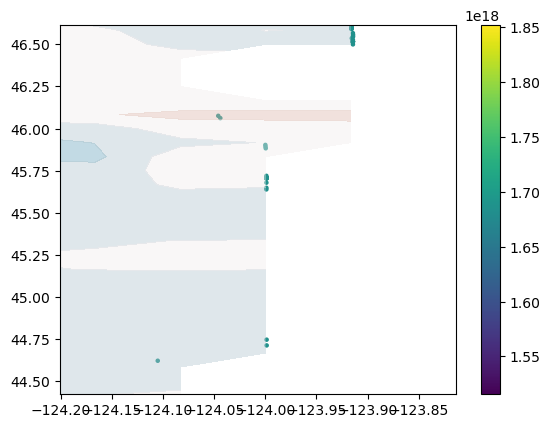

In [18]:
N = 2
a = plt.scatter(trajectory1.lon[:,-1],trajectory1.lat[:,-1],s = 5,c = trajectory1.time[:,-1]) #lat # z
#b = plt.scatter(trajectory1.lon[-1,:],trajectory1.lat[-1,:],s = 5,c = trajectory1.time[-1,:]) #lat # z
plt.contourf(uv.longitude,uv.latitude,uv.uo[0,0,:,:],alpha=0.4, levels = np.linspace(-0.5,0.5,12),cmap=cmocean.cm.balance)
plt.colorbar(a)
plt.ylim(np.min(trajectory1.lat[N,:]-0.1),np.max(trajectory1.lat[N,:])+0.1)
plt.xlim(np.min(trajectory1.lon[N,:]-0.1),np.max(trajectory1.lon[N,:])+0.1)

(-127.45596313476562, -122.01224517822266)

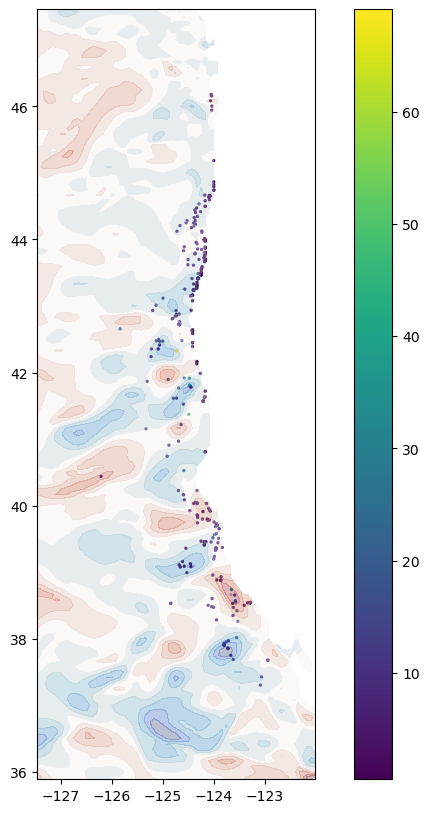

In [19]:
plt.subplots(figsize = (10,10))
a = plt.scatter(Lon[100],Lat[100],c = Z[100],s=2)
#a = plt.scatter(Lon[-1],Lat[-1],c = Z[-1])
plt.colorbar(a)
f = 1/np.cos(40*np.pi/180)
plt.gca().set_aspect(f)
plt.contourf(uv.longitude,uv.latitude,uv.uo[0,0,:,:],alpha=0.3, levels = np.linspace(-0.5,0.5,12),cmap=cmocean.cm.balance)

plt.ylim(np.min(trajectory1.lat)-0.5,np.max(trajectory1.lat)+0.5)
plt.xlim(np.min(trajectory1.lon)-0.5,np.max(trajectory1.lon)+0.5)

In [35]:

def animationfuction(outfile,fps = 10):
    data = xr.open_zarr(outfile)
    time = data.time[0,:]
    #Lat,Lon,Z = order_data_bytime(data,odt,time)

    #fig = plt.figure(figsize=(8,8),)
    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={'projection': crs.Mercator()})
    
    ax.set_extent([-126, -122, 35,47], crs=crs.PlateCarree())    

    ax.grid()
    f = 1/np.cos(40*np.pi/180)
    plt.gca().set_aspect(f)

    
    a = ax.scatter(Lon[0],Lat[0],c = Z[0],s=0.5,cmap = cmocean.cm.deep,alpha=0.5,
                                  zorder=3,transform=crs.PlateCarree(),vmin = 0,vmax = 80)
    cbar = fig.colorbar(a, location='right',aspect=30,shrink=1,pad=0.01)
    cbar.set_label('Depth [m]')
    def update(frame):
        ax.clear()
        ax.set_extent([-126, -122, 35,47], crs=crs.PlateCarree())    
        ax.grid()
        plt.contourf(uv.longitude,uv.latitude,uv.uo[frame//8,0,:,:],alpha=0.3, levels = np.linspace(-0.5,0.5,12),cmap=cmocean.cm.balance,transform=crs.PlateCarree())
        ax.scatter(Lon[frame],Lat[frame],c = Z[frame],s=2,transform=crs.PlateCarree(),vmin = 0,vmax = 80)
    return animation.FuncAnimation(fig, update, frames=np.arange(0,len(Z),1))


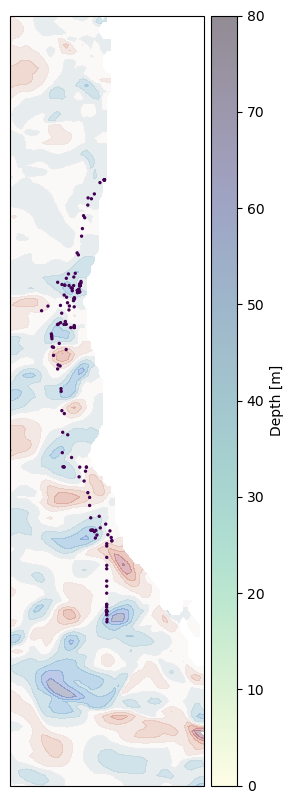

In [36]:
odt = 3
animation1 = animationfuction(outfile)
HTML(animation1.to_jshtml())
f = example_dataset_folder+"/backtrajectories_animation.gif"
FFwriter = animation.FFMpegWriter()
animation1.save(f, writer = FFwriter)

In [22]:
lastz = []
for i in range(len(trajectory1.z[:,-1])):
    message = 'nan'
    count = 0
    while message == 'nan':
        try: 
            count-= 1  
            int(np.array(trajectory1.z[i,count])) 
            message = 'good'  
        except ValueError:
            message = 'nan'
    lastz.append(float(np.array(trajectory1.z[i,count])) )    


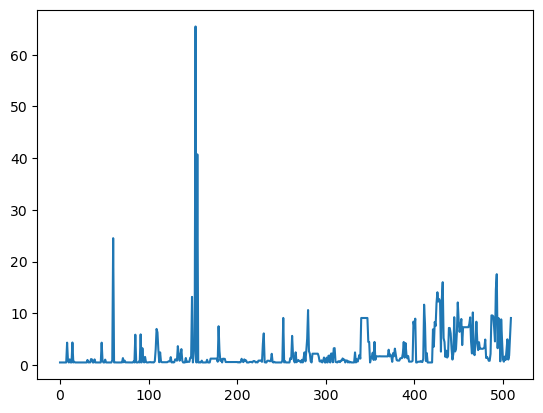

In [23]:
plt.plot(lastz)

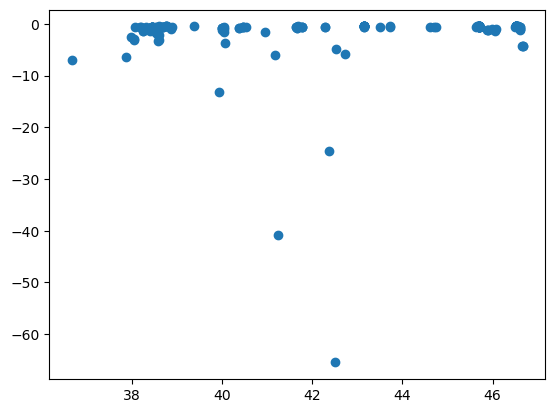

In [24]:
plt.scatter(trajectory1.lat[:,-1],-np.array(lastz))

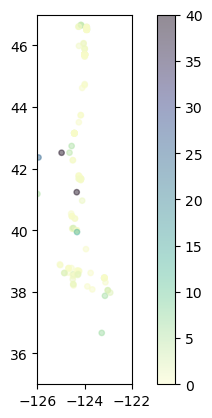

In [37]:
a = plt.scatter(trajectory1.lon[:,-1],trajectory1.lat[:,-1],s = 15,alpha = 0.5,c = trajectory1.z[:,-1],cmap = cmocean.cm.deep,vmin = 0,vmax=40)
plt.colorbar(a)
plt.xlim(-126,-122)
plt.ylim(35,47)
f = 1/np.cos(40*np.pi/180)
plt.gca().set_aspect(f)